# Grocery Inventory: Unsupervised Data Analysis

**Purpose:** Fully automated analysis from raw `food.csv` data through profiling, PCA, k-means clustering, validation, and presentation-ready evidence.

This notebook mirrors the weekly deliverables. Run it from top to bottom using **Run All**. Figures and tables are saved automatically into `outputs/`.

## Project questions
1. What nutritional patterns and product "tribes" occur in the inventory?
2. Which features drive those clusters?
3. Which grocery categories align with each cluster?
4. Which clusters are well separated, and where do their boundaries overlap?
5. Are products with wellness-related wording nutritionally aligned with healthier clusters?

## 0. Environment setup

The first cell imports the libraries used throughout the project. If an import fails, run this once in the VS Code terminal:

`python -m pip install pandas numpy matplotlib seaborn scikit-learn jupyter ipykernel`

System Validation

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

RANDOM_STATE = 42
CHOSEN_K = 5
TOP_CATEGORIES = 10

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
print(f"Outputs will be saved to: {OUTPUT_DIR.resolve()}")

Matplotlib is building the font cache; this may take a moment.


Outputs will be saved to: C:\Users\danie\AppData\Local\GitHub-Projects\transfer\Data-Design-Project\notebooks\outputs


## 1. Load and validate the raw data

The path finder supports common repository layouts. It looks for `food.csv` in the current folder, `data/`, or one level above the notebook.

In [2]:
CANDIDATE_PATHS = [
    Path("food.csv"),
    Path("data/food.csv"),
    Path("../food.csv"),
    Path("../data/food.csv"),
]

DATA_PATH = next((p for p in CANDIDATE_PATHS if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "food.csv was not found. Put it beside the notebook or in a data/ folder."
    )

df = pd.read_csv(DATA_PATH)
print(f"Loaded {DATA_PATH}: {df.shape[0]:,} rows x {df.shape[1]} columns")
display(df.head())

Loaded ..\data\food.csv: 7,413 rows x 10 columns


,Category,Description,Data.Carbohydrate,Data.Fiber,Data.Kilocalories,Data.Protein,Data.Sugar Total,Data.Water,Data.Fat.Saturated Fat,Data.Fat.Total Lipid
0,BUTTER,"BUTTER,WITH SALT",0.06,0.0,717,0.85,0.06,15.87,51.368,81.11
1,BUTTER,"BUTTER,WHIPPED,WITH SALT",0.06,0.0,717,0.85,0.06,15.87,50.489,81.11
2,BUTTER OIL,"BUTTER OIL,ANHYDROUS",0.00,0.0,876,0.28,0.00,0.24,61.924,99.48
3,CHEESE,"CHEESE,BLUE",2.34,0.0,353,21.40,0.50,42.41,18.669,28.74
4,CHEESE,"CHEESE,BRICK",2.79,0.0,371,23.24,0.51,41.11,18.764,29.68


In [3]:
EXPECTED_TEXT = ["Category", "Description"]
EXPECTED_NUMERIC = [
    "Data.Carbohydrate",
    "Data.Fiber",
    "Data.Kilocalories",
    "Data.Protein",
    "Data.Sugar Total",
    "Data.Water",
    "Data.Fat.Saturated Fat",
    "Data.Fat.Total Lipid",
]
EXPECTED_COLUMNS = EXPECTED_TEXT + EXPECTED_NUMERIC

missing_columns = [c for c in EXPECTED_COLUMNS if c not in df.columns]
if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

for c in EXPECTED_NUMERIC:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df["Category"] = df["Category"].fillna("NO CATEGORY").astype(str).str.strip()
df["Description"] = df["Description"].fillna("UNKNOWN DESCRIPTION").astype(str).str.strip()

print("Missing values by column:")
display(df[EXPECTED_COLUMNS].isna().sum().to_frame("Missing"))
print(f"Duplicate full rows: {df.duplicated().sum():,}")
print(f"Unique categories: {df['Category'].nunique():,}")

Missing values by column:


,Missing
Category,0
Description,0
Data.Carbohydrate,0
Data.Fiber,0
Data.Kilocalories,0
Data.Protein,0
Data.Sugar Total,0
Data.Water,0
Data.Fat.Saturated Fat,0
Data.Fat.Total Lipid,0


Duplicate full rows: 1
Unique categories: 1,181


# Deliverable 2: Data Audit and EDA

## 2.1 Summary statistics and category audit

In [4]:
summary = df[EXPECTED_NUMERIC].describe().T
summary["skewness"] = df[EXPECTED_NUMERIC].skew()
summary.to_csv(OUTPUT_DIR / "numeric_summary.csv")
display(summary.round(3))

category_counts = df["Category"].value_counts().rename_axis("Category").reset_index(name="Count")
category_counts.to_csv(OUTPUT_DIR / "category_counts.csv", index=False)
display(category_counts.head(15))

,count,mean,std,min,25%,50%,75%,max,skewness
Data.Carbohydrate,7413.0,21.785,27.123,0.0,0.490,9.290,30.590,100.00,1.227
Data.Fiber,7413.0,1.993,4.293,0.0,0.000,0.300,2.300,79.00,5.707
Data.Kilocalories,7413.0,219.656,171.669,0.0,82.000,181.000,331.000,902.00,1.272
Data.Protein,7413.0,10.810,10.484,0.0,2.130,7.270,18.580,88.32,1.382
Data.Sugar Total,7413.0,6.398,13.964,0.0,0.000,0.220,4.650,99.91,3.053
Data.Water,7413.0,55.168,30.906,0.0,30.800,64.280,79.960,100.00,-0.616
Data.Fat.Saturated Fat,7413.0,3.253,6.520,0.0,0.115,1.157,3.893,95.60,6.780
Data.Fat.Total Lipid,7413.0,10.220,16.499,0.0,0.740,4.280,12.950,100.00,3.361


,Category,Count
0,BEEF,457
1,PORK,304
2,CEREALS RTE,291
3,BABYFOOD,221
4,No Category,198
5,LAMB,198
6,SOUP,188
7,CHICKEN,163
8,CEREALS,132
9,FAST FOODS,130


## 2.2 Histograms

Histograms show the shape, skewness, and possible multiple populations in each nutrient.

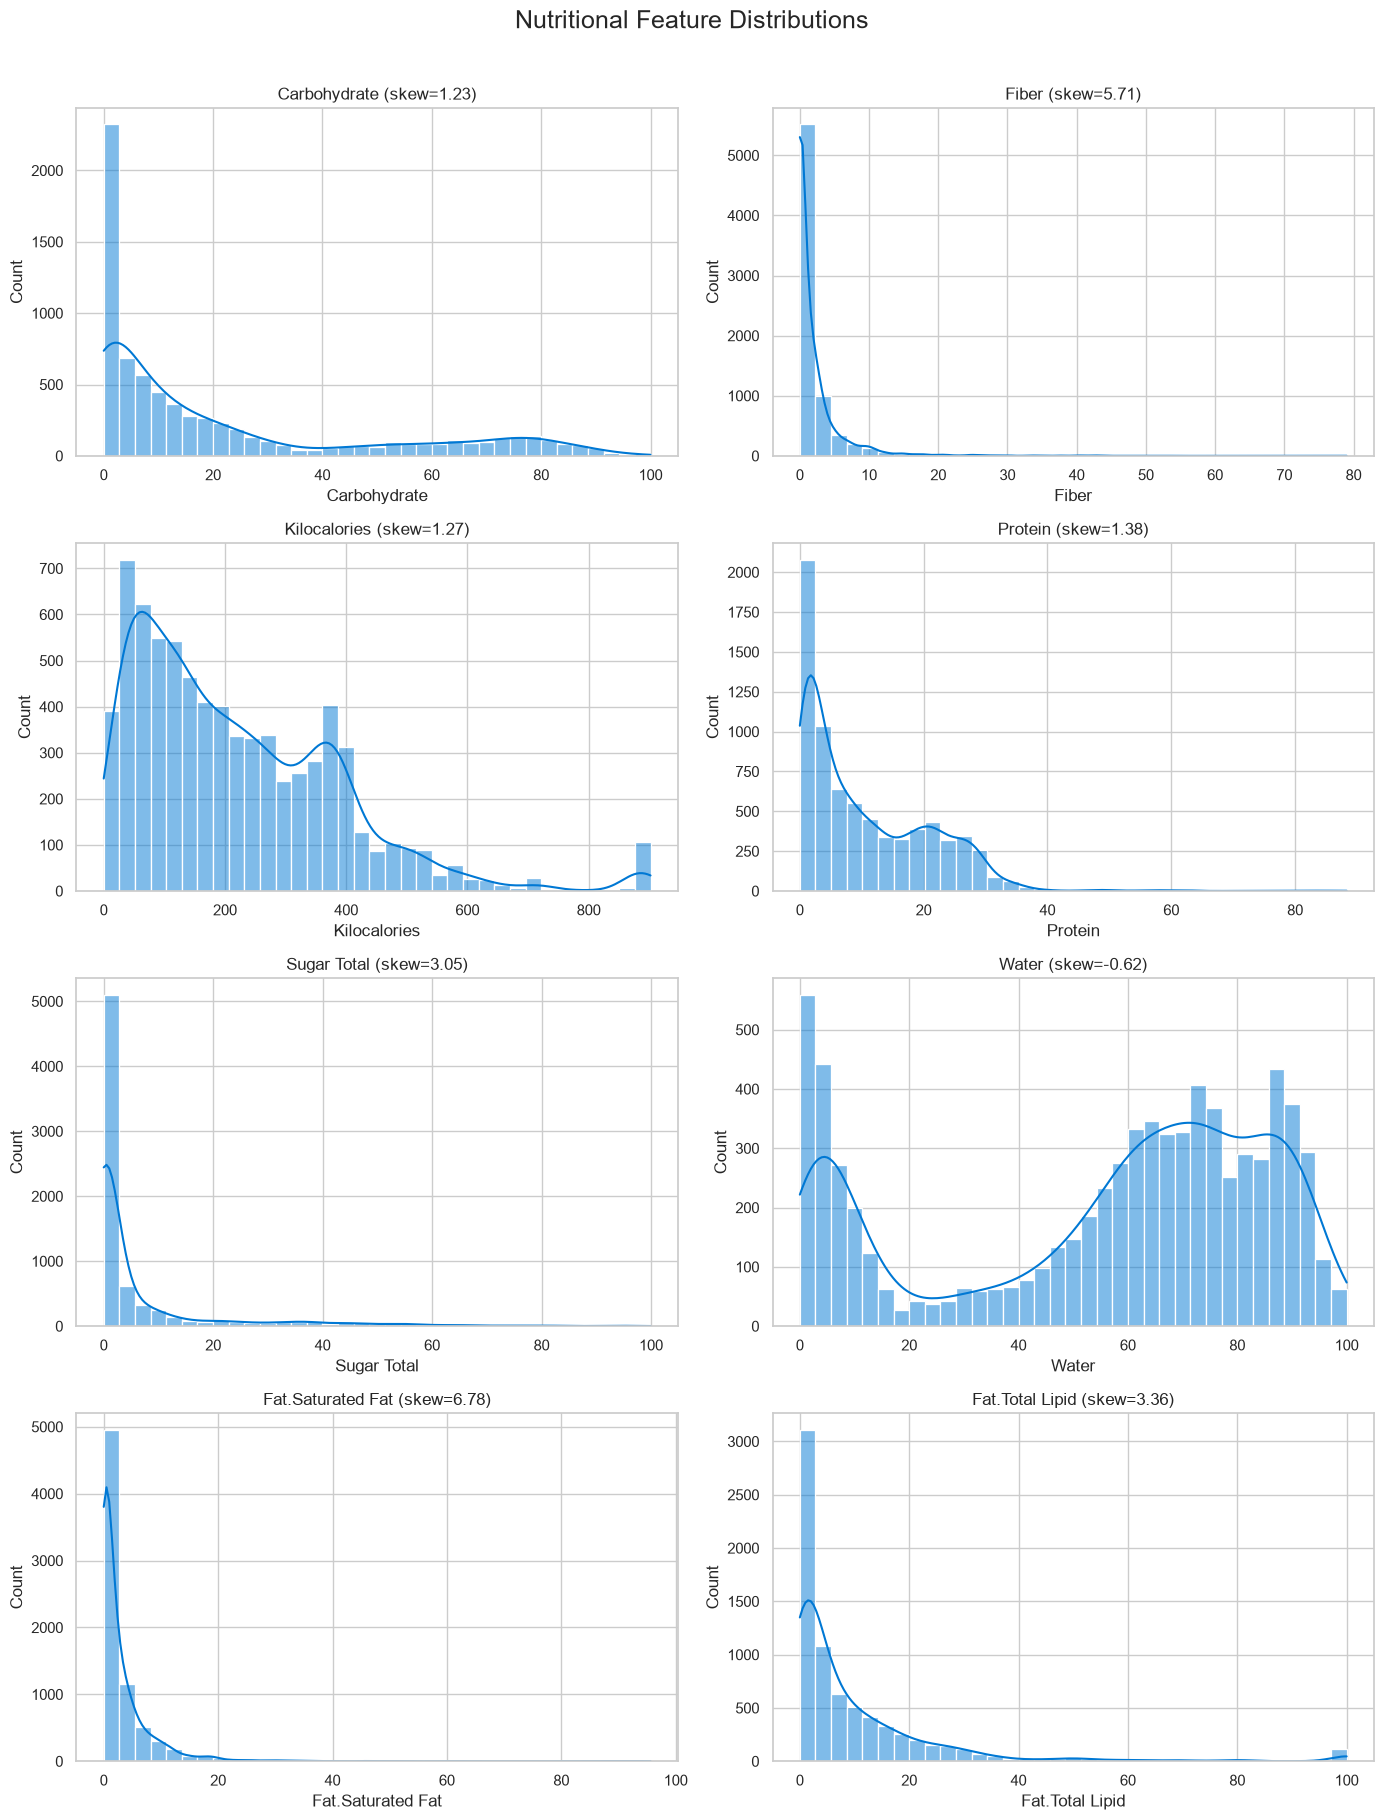

In [5]:
fig, axes = plt.subplots(4, 2, figsize=(14, 18))
for ax, col in zip(axes.flat, EXPECTED_NUMERIC):
    sns.histplot(df[col].dropna(), bins=35, kde=True, ax=ax, color="#0078D4")
    ax.set_title(f"{col.replace('Data.', '')} (skew={df[col].skew():.2f})")
    ax.set_xlabel(col.replace("Data.", ""))
plt.suptitle("Nutritional Feature Distributions", fontsize=18, y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "histograms.png", dpi=200, bbox_inches="tight")
plt.show()

## 2.3 Standard boxplots

These retain the raw units. Upper outliers are expected for heavily right-skewed nutrients and should not automatically be deleted.

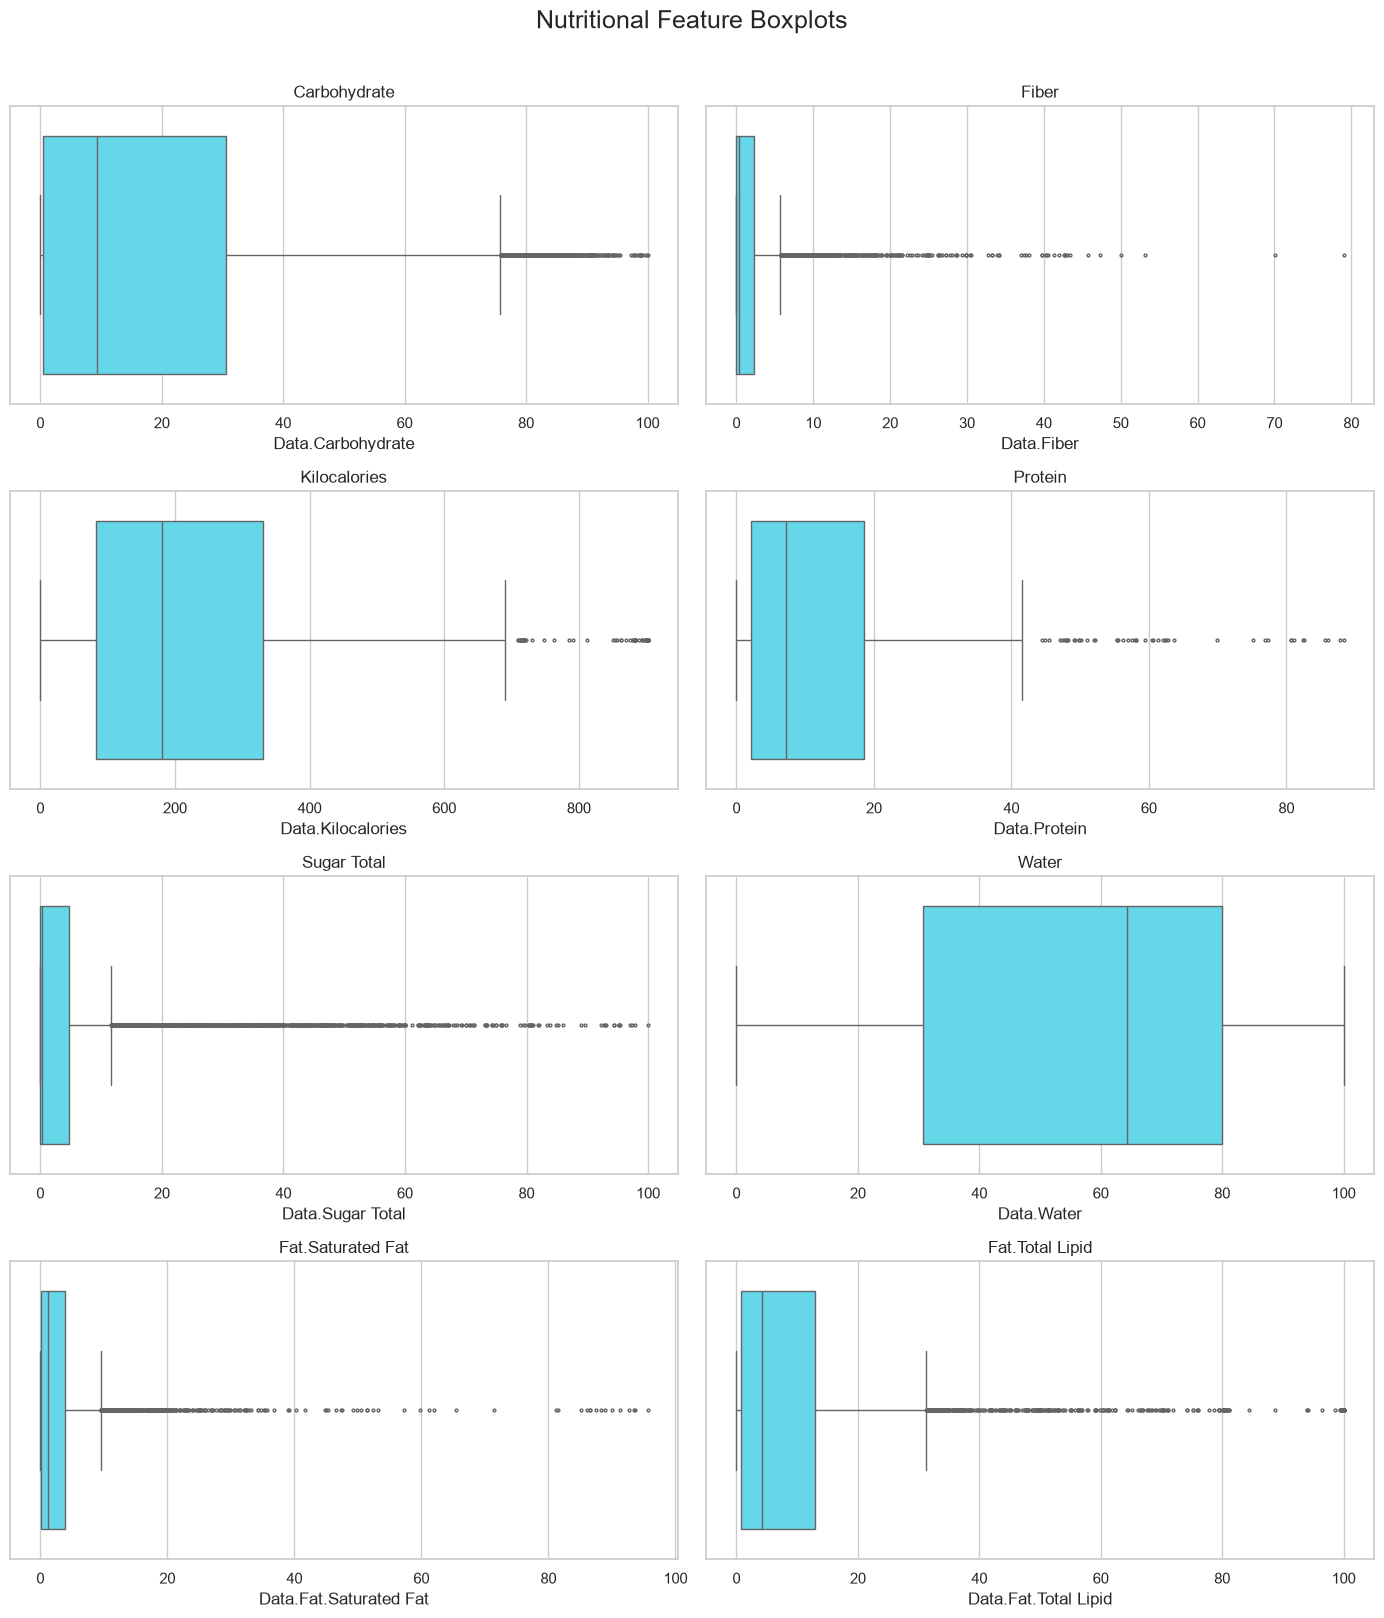

In [6]:
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
for ax, col in zip(axes.flat, EXPECTED_NUMERIC):
    sns.boxplot(x=df[col], ax=ax, color="#50E6FF", fliersize=2)
    ax.set_title(col.replace("Data.", ""))
plt.suptitle("Nutritional Feature Boxplots", fontsize=18, y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "boxplots.png", dpi=200, bbox_inches="tight")
plt.show()

## 2.4 Correlation matrix

Pearson correlation measures linear relationships. Strong positive or negative values indicate nutrients that tend to vary together or in opposite directions.

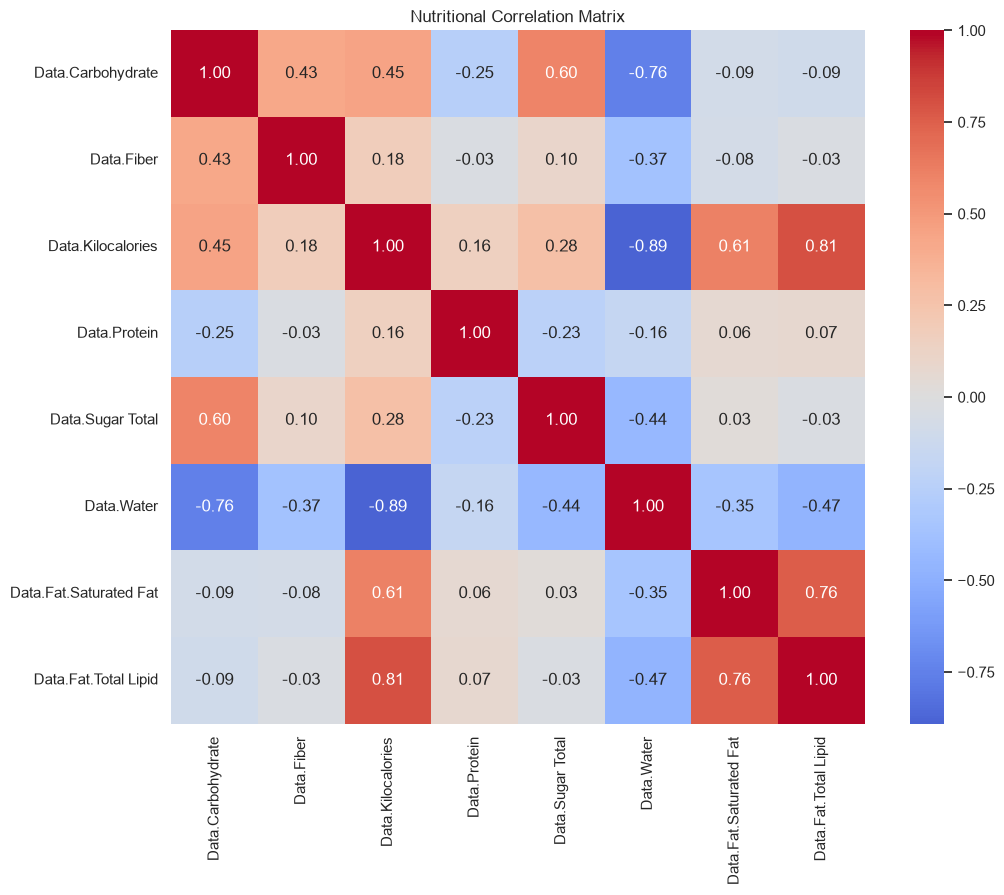

,Feature 1,Feature 2,Correlation,Absolute Correlation
21,Data.Kilocalories,Data.Water,-0.891,0.891
23,Data.Kilocalories,Data.Fat.Total Lipid,0.806,0.806
55,Data.Fat.Saturated Fat,Data.Fat.Total Lipid,0.762,0.762
5,Data.Carbohydrate,Data.Water,-0.757,0.757
22,Data.Kilocalories,Data.Fat.Saturated Fat,0.613,0.613
4,Data.Carbohydrate,Data.Sugar Total,0.601,0.601
47,Data.Water,Data.Fat.Total Lipid,-0.473,0.473
2,Data.Carbohydrate,Data.Kilocalories,0.453,0.453
37,Data.Sugar Total,Data.Water,-0.435,0.435
1,Data.Carbohydrate,Data.Fiber,0.431,0.431


In [7]:
corr = df[EXPECTED_NUMERIC].corr()
corr.to_csv(OUTPUT_DIR / "correlation_matrix.csv")

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Nutritional Correlation Matrix")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "correlation_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

pairs = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
        .stack()
        .rename("Correlation")
        .reset_index()
        .rename(columns={"level_0": "Feature 1", "level_1": "Feature 2"})
)
pairs["Absolute Correlation"] = pairs["Correlation"].abs()
strong_pairs = pairs.sort_values("Absolute Correlation", ascending=False)
strong_pairs.to_csv(OUTPUT_DIR / "ranked_correlations.csv", index=False)
display(strong_pairs.head(10).round(3))

# Deliverable 3: Critical Thinking and Data Investigation

## 3.1 Column meanings

- **Category:** source-provided grocery category.
- **Description:** individual product description.
- **Carbohydrate:** total carbohydrate amount.
- **Fiber:** dietary fiber amount.
- **Kilocalories:** energy content.
- **Protein:** protein amount.
- **Sugar Total:** total sugar amount.
- **Water:** water/moisture content.
- **Saturated Fat:** saturated-fat amount.
- **Total Lipid:** total fat amount.

Use the ranked-correlation table above to annotate the strongest nutrient groups.

## 3.2 Select three complementary features and test them

The automatic feature-selection rule favors high variability while penalizing redundancy. The notebook evaluates every three-feature combination using standardized variance and absolute pairwise correlation. This is a transparent heuristic, not a supervised classifier.

In [8]:
from itertools import combinations

X_complete = df[EXPECTED_NUMERIC].dropna()
scaled_for_selection = pd.DataFrame(
    StandardScaler().fit_transform(X_complete),
    columns=EXPECTED_NUMERIC,
    index=X_complete.index,
)

selection_rows = []
for combo in combinations(EXPECTED_NUMERIC, 3):
    sub_corr = scaled_for_selection[list(combo)].corr().abs()
    mean_redundancy = sub_corr.where(np.triu(np.ones((3, 3)), k=1).astype(bool)).stack().mean()
    raw_spread = df[list(combo)].std().rank(pct=True).mean()
    score = raw_spread - mean_redundancy
    selection_rows.append((*combo, mean_redundancy, raw_spread, score))

selection = pd.DataFrame(selection_rows, columns=["Feature 1", "Feature 2", "Feature 3", "Mean redundancy", "Spread rank", "Score"])
selection = selection.sort_values("Score", ascending=False)
SELECTED_3 = selection.iloc[0][["Feature 1", "Feature 2", "Feature 3"]].tolist()
print("Suggested three features:", SELECTED_3)
display(selection.head(10).round(3))

Suggested three features: ['Data.Fiber', 'Data.Protein', 'Data.Fat.Total Lipid']


,Feature 1,Feature 2,Feature 3,Mean redundancy,Spread rank,Score
29,Data.Fiber,Data.Protein,Data.Fat.Total Lipid,0.045,0.667,0.621
32,Data.Fiber,Data.Sugar Total,Data.Fat.Total Lipid,0.053,0.667,0.614
28,Data.Fiber,Data.Protein,Data.Fat.Saturated Fat,0.058,0.667,0.608
31,Data.Fiber,Data.Sugar Total,Data.Fat.Saturated Fat,0.067,0.667,0.600
47,Data.Protein,Data.Sugar Total,Data.Fat.Saturated Fat,0.107,0.667,0.560
48,Data.Protein,Data.Sugar Total,Data.Fat.Total Lipid,0.112,0.667,0.555
26,Data.Fiber,Data.Protein,Data.Sugar Total,0.120,0.667,0.547
21,Data.Fiber,Data.Kilocalories,Data.Protein,0.123,0.667,0.543
13,Data.Carbohydrate,Data.Protein,Data.Fat.Saturated Fat,0.134,0.667,0.533
14,Data.Carbohydrate,Data.Protein,Data.Fat.Total Lipid,0.140,0.667,0.527


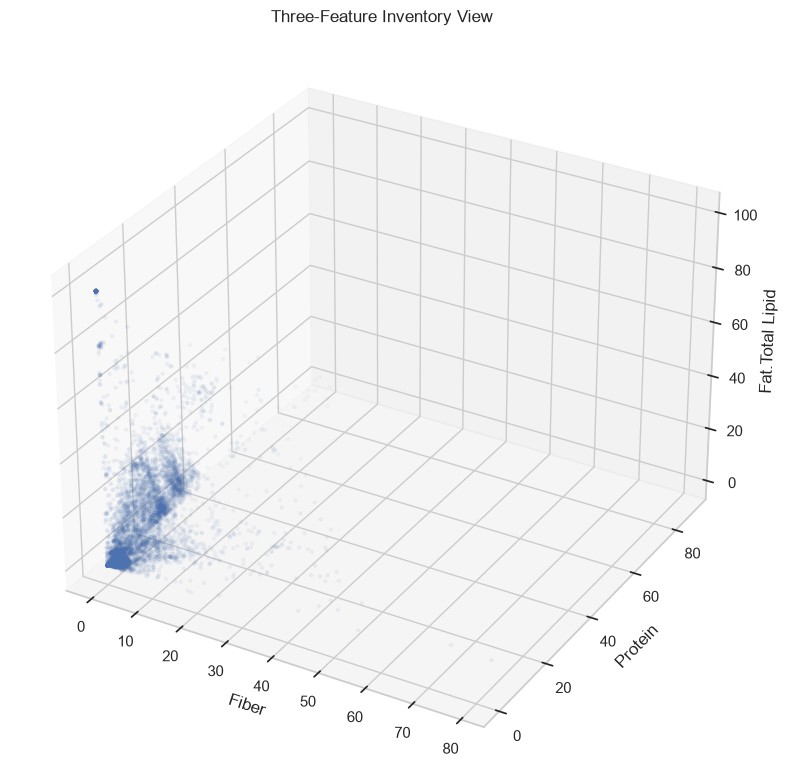

In [9]:
plot_3 = df[SELECTED_3 + ["Category"]].dropna().copy()
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(plot_3[SELECTED_3[0]], plot_3[SELECTED_3[1]], plot_3[SELECTED_3[2]], s=5, alpha=0.25)
ax.set_xlabel(SELECTED_3[0].replace("Data.", ""))
ax.set_ylabel(SELECTED_3[1].replace("Data.", ""))
ax.set_zlabel(SELECTED_3[2].replace("Data.", ""))
ax.set_title("Three-Feature Inventory View")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "three_feature_scatter.png", dpi=200, bbox_inches="tight")
plt.show()

## 3.3 Outlier and possible misfit investigation

This uses standardized absolute z-scores. A row is flagged when any nutrient is at least 4 standard deviations from the feature mean. Flagging means “investigate,” not “delete.”

In [10]:
analysis_mask = df[EXPECTED_NUMERIC].notna().all(axis=1)
X_raw = df.loc[analysis_mask, EXPECTED_NUMERIC].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)
z = pd.DataFrame(X_scaled, columns=EXPECTED_NUMERIC, index=X_raw.index)

outliers = df.loc[analysis_mask, ["Category", "Description"] + EXPECTED_NUMERIC].copy()
outliers["Maximum absolute z-score"] = z.abs().max(axis=1)
outliers["Most unusual feature"] = z.abs().idxmax(axis=1)
outliers = outliers[outliers["Maximum absolute z-score"] >= 4].sort_values("Maximum absolute z-score", ascending=False)
outliers.to_csv(OUTPUT_DIR / "outlier_candidates.csv", index=False)
print(f"Flagged {len(outliers):,} possible outlier rows.")
display(outliers.head(25))

Flagged 373 possible outlier rows.


,Category,Description,Data.Carbohydrate,Data.Fiber,Data.Kilocalories,Data.Protein,Data.Sugar Total,Data.Water,Data.Fat.Saturated Fat,Data.Fat.Total Lipid,Maximum absolute z-score,Most unusual feature
6124,CORN BRAN,"CORN BRAN,CRUDE",85.64,79.000000,224,8.36,0.00,4.71,0.130,0.92,17.939514,Data.Fiber
3587,FUNGI,"FUNGI,CLOUD EARS,DRIED",73.01,70.099998,284,9.25,0.00,14.80,0.000,0.73,15.866170,Data.Fiber
643,FISH OIL,"FISH OIL,MENHADEN,FULLY HYDR",0.00,0.000000,902,0.00,0.00,0.00,95.600,100.00,14.165368,Data.Fat.Saturated Fat
692,OIL,"OIL,VEG,INDUSTRIAL,PALM KERNEL (HYDROGENATED),...",0.00,0.000000,884,0.00,0.00,0.05,93.701,100.00,13.874075,Data.Fat.Saturated Fat
696,OIL,"OIL,INDUS,COCNT (HYDR),WHIPPED TOPPINGS&COFFEE...",0.00,0.000000,880,0.00,0.00,0.07,93.536,99.50,13.848766,Data.Fat.Saturated Fat
693,OIL,"OIL,VEG,INDUS,PALM KERNEL (HYDROG),CONFECTION FAT",0.00,0.000000,884,0.00,0.00,0.04,92.614,100.00,13.707338,Data.Fat.Saturated Fat
620,SHORTENING CONFECTIONERY,"SHORTENING CONFECTIONERY,COCNT (HYDR)&OR PALM ...",0.00,0.000000,884,0.00,0.00,0.00,91.300,100.00,13.505779,Data.Fat.Saturated Fat
627,OIL,"OIL,VEG,NUTMEG BUTTER",0.00,0.000000,884,0.00,0.00,0.00,90.000,100.00,13.306369,Data.Fat.Saturated Fat
695,OIL,"OIL,VEG,INDUSTRIAL,PALM KERNEL (HYDROG) WHIPPE...",0.00,0.000000,884,0.00,0.00,0.04,88.965,100.00,13.147607,Data.Fat.Saturated Fat
698,OIL,"OIL,INDUSTRIAL,PALM KERNEL (HYDROGENATED),FILL...",0.00,0.000000,884,0.00,0.00,0.08,88.209,100.00,13.031642,Data.Fat.Saturated Fat


# Deliverable 4: PCA and k-Means Pipeline

## 4.1 Standardization and PCA

PCA and k-means use the eight standardized nutritional features. Text labels are retained for interpretation but are not used to form clusters.

In [11]:
pca_full = PCA(n_components=len(EXPECTED_NUMERIC), random_state=RANDOM_STATE)
X_pca_full = pca_full.fit_transform(X_scaled)

variance_table = pd.DataFrame({
    "Component": [f"PC{i}" for i in range(1, len(EXPECTED_NUMERIC)+1)],
    "Explained Variance": pca_full.explained_variance_ratio_,
})
variance_table["Cumulative Variance"] = variance_table["Explained Variance"].cumsum()
variance_table.to_csv(OUTPUT_DIR / "pca_variance.csv", index=False)
display(variance_table.style.format({"Explained Variance": "{:.2%}", "Cumulative Variance": "{:.2%}"}))

print(f"PC1 + PC2 capture {variance_table.loc[1, 'Cumulative Variance']:.2%} of standardized variance.")

,Component,Explained Variance,Cumulative Variance
0,PC1,41.53%,41.53%
1,PC2,25.86%,67.38%
2,PC3,13.70%,81.08%
3,PC4,10.30%,91.39%
4,PC5,5.27%,96.66%
5,PC6,3.18%,99.84%
6,PC7,0.11%,99.95%
7,PC8,0.05%,100.00%


PC1 + PC2 capture 67.38% of standardized variance.


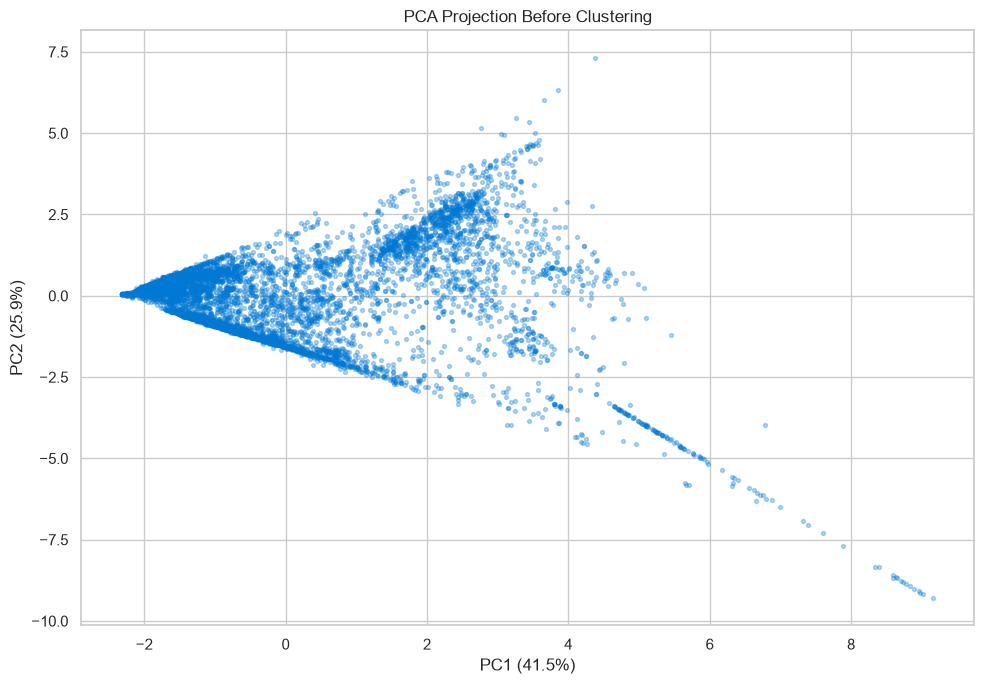

In [12]:
pca_2 = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca_2.fit_transform(X_scaled)
pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"], index=X_raw.index)

plt.figure(figsize=(10, 7))
plt.scatter(pca_df["PC1"], pca_df["PC2"], s=8, alpha=0.3, color="#0078D4")
plt.xlabel(f"PC1 ({pca_2.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 ({pca_2.explained_variance_ratio_[1]:.1%})")
plt.title("PCA Projection Before Clustering")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "pca_unclustered.png", dpi=200, bbox_inches="tight")
plt.show()

## 4.2 Elbow method, k = 2 through 10

`KMeans.inertia_` is the within-cluster sum of squared distances (WCSS). The random seed and multiple initializations make the results reproducible.

,k,WCSS,Average Silhouette,WCSS Reduction,Percent Reduction
0,2,39797.4903,0.4724,NaN,NaN
1,3,31126.0115,0.4840,8671.4788,21.7890
2,4,24051.5293,0.4149,7074.4822,22.7285
3,5,19907.7965,0.4287,4143.7328,17.2286
4,6,17059.3171,0.4397,2848.4794,14.3084
5,7,14947.4403,0.4466,2111.8768,12.3796
6,8,13290.5294,0.4333,1656.9109,11.0849
7,9,12264.2959,0.4347,1026.2335,7.7215
8,10,11415.3136,0.4308,848.9824,6.9224


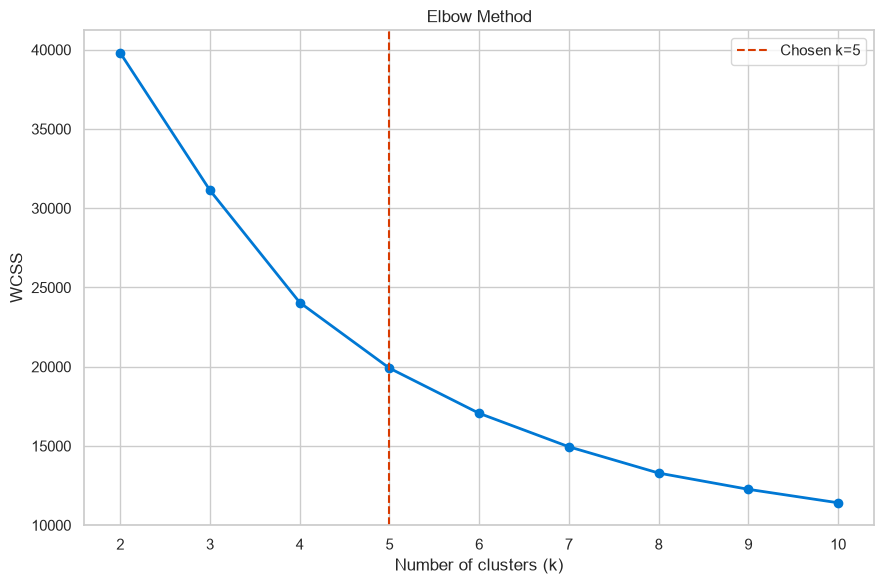

In [13]:
elbow_rows = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels_k = model.fit_predict(X_scaled)
    elbow_rows.append({
        "k": k,
        "WCSS": model.inertia_,
        "Average Silhouette": silhouette_score(X_scaled, labels_k),
    })

elbow = pd.DataFrame(elbow_rows)
elbow["WCSS Reduction"] = -elbow["WCSS"].diff()
elbow["Percent Reduction"] = -elbow["WCSS"].pct_change() * 100
elbow.to_csv(OUTPUT_DIR / "elbow_and_silhouette_by_k.csv", index=False)
display(elbow.round(4))

fig, ax1 = plt.subplots(figsize=(9, 6))
ax1.plot(elbow["k"], elbow["WCSS"], marker="o", linewidth=2, color="#0078D4")
ax1.axvline(CHOSEN_K, color="#D83B01", linestyle="--", label=f"Chosen k={CHOSEN_K}")
ax1.set_xlabel("Number of clusters (k)")
ax1.set_ylabel("WCSS")
ax1.set_title("Elbow Method")
ax1.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "elbow_plot.png", dpi=200, bbox_inches="tight")
plt.show()

## 4.3 Final k-means model and PCA-space visualization

The final model uses `k=5`, matching the elbow analysis. Cluster numbers are arbitrary identifiers, not rankings.

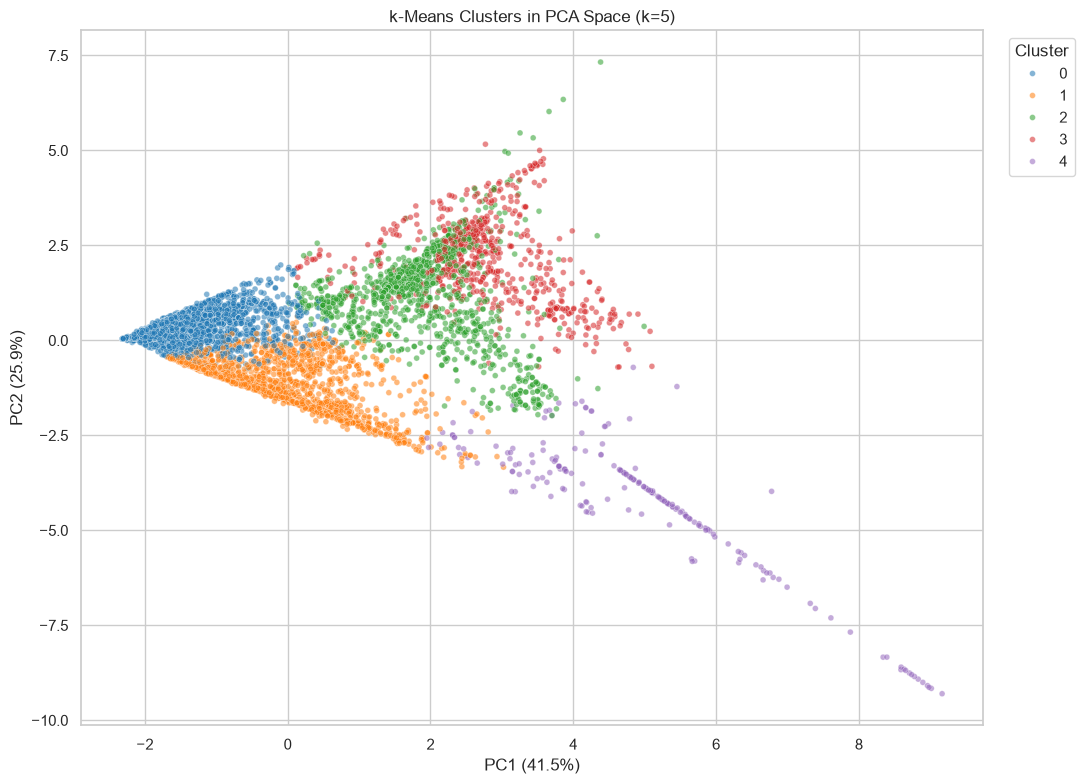

In [14]:
kmeans = KMeans(n_clusters=CHOSEN_K, random_state=RANDOM_STATE, n_init=20)
cluster_labels = kmeans.fit_predict(X_scaled)

results = df.loc[analysis_mask].copy()
results["Cluster"] = cluster_labels
results["PC1"] = pca_df["PC1"]
results["PC2"] = pca_df["PC2"]

plt.figure(figsize=(11, 8))
sns.scatterplot(data=results, x="PC1", y="PC2", hue="Cluster", palette="tab10", s=18, alpha=0.55)
plt.xlabel(f"PC1 ({pca_2.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 ({pca_2.explained_variance_ratio_[1]:.1%})")
plt.title(f"k-Means Clusters in PCA Space (k={CHOSEN_K})")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "clusters_pca.png", dpi=200, bbox_inches="tight")
plt.show()

## 4.4 Explainable clustering: centroids and PCA loadings

Because k-means is unsupervised, it does not make class predictions in the conventional supervised-learning sense. The most influential features are identified through:

1. **Standardized cluster centroids:** features that most distinguish each cluster from the overall inventory.
2. **PCA loadings:** features that drive the PC1 and PC2 visualization.

,Data.Carbohydrate,Data.Fiber,Data.Kilocalories,Data.Protein,Data.Sugar Total,Data.Water,Data.Fat.Saturated Fat,Data.Fat.Total Lipid
Cluster,,,,,,,,
0,12.28,1.47,75.62,2.82,3.79,81.50,0.58,1.77
1,3.81,0.25,218.49,21.82,0.58,60.06,4.34,12.48
2,61.83,7.11,381.50,10.74,5.09,11.94,2.49,12.04
3,71.62,2.53,404.50,5.69,46.25,8.90,4.72,11.46
4,3.04,0.79,770.67,2.45,0.75,9.01,26.41,84.74


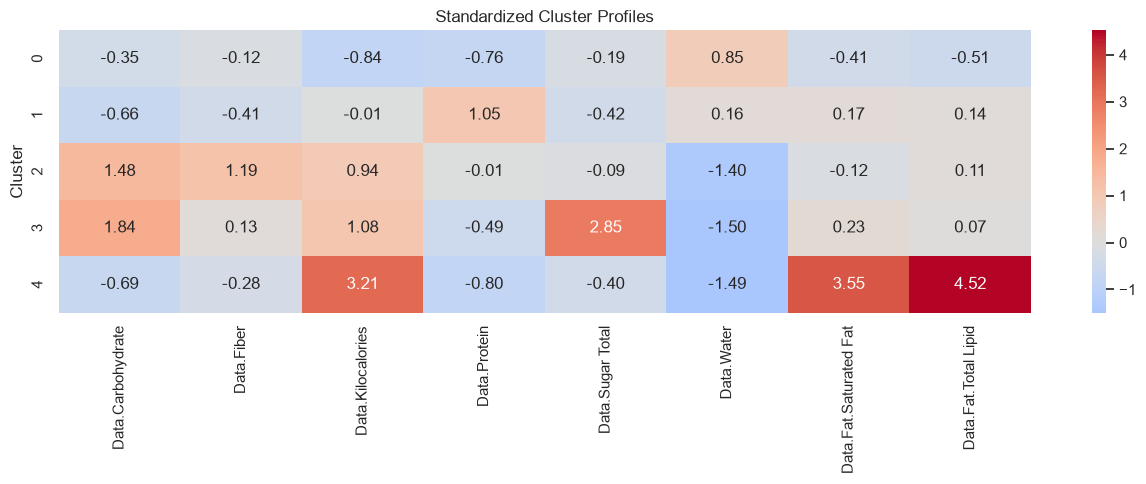

,PC1 loading,PC2 loading,Combined absolute influence
Data.Carbohydrate,0.339,0.509,0.848
Data.Fat.Total Lipid,0.376,-0.444,0.820
Data.Fat.Saturated Fat,0.325,-0.429,0.754
Data.Kilocalories,0.526,-0.146,0.672
Data.Water,-0.515,-0.126,0.641
Data.Sugar Total,0.251,0.389,0.640
Data.Fiber,0.179,0.311,0.491
Data.Protein,0.028,-0.272,0.300


In [15]:
centroids_z = pd.DataFrame(kmeans.cluster_centers_, columns=EXPECTED_NUMERIC)
centroids_z.index.name = "Cluster"
centroids_z.to_csv(OUTPUT_DIR / "cluster_centroids_standardized.csv")

centroids_raw = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=EXPECTED_NUMERIC,
)
centroids_raw.index.name = "Cluster"
centroids_raw.to_csv(OUTPUT_DIR / "cluster_centroids_raw_units.csv")

display(centroids_raw.round(2))

plt.figure(figsize=(13, 5))
sns.heatmap(centroids_z, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Standardized Cluster Profiles")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "cluster_profile_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

loadings = pd.DataFrame(
    pca_2.components_.T,
    index=EXPECTED_NUMERIC,
    columns=["PC1 loading", "PC2 loading"],
)
loadings["Combined absolute influence"] = loadings.abs().sum(axis=1)
loadings = loadings.sort_values("Combined absolute influence", ascending=False)
loadings.to_csv(OUTPUT_DIR / "pca_loadings.csv")
display(loadings.round(3))

# Deliverable 5: Cluster Composition and Validation

## 5.1 Cluster composition and purity

The full grouped table is preserved in CSV. For readable charts, the notebook shows the ten most frequent categories within each cluster rather than attempting to display every category at once.

,Cluster,Category,Count,Cluster Total,Share within Cluster
20,0,BABYFOOD,194,2879,0.067385
530,0,SOUP,175,2879,0.060785
73,0,CAMPBELL SOUP COMPANY,107,2879,0.037166
33,0,BEANS,89,2879,0.030914
106,0,CEREALS,66,2879,0.022925
459,0,POTATOES,64,2879,0.022230
4,0,ALCOHOLIC BEV,58,2879,0.020146
391,0,No Category,56,2879,0.019451
68,0,CAMPBELL,54,2879,0.018757
549,0,SQUASH,45,2879,0.015630


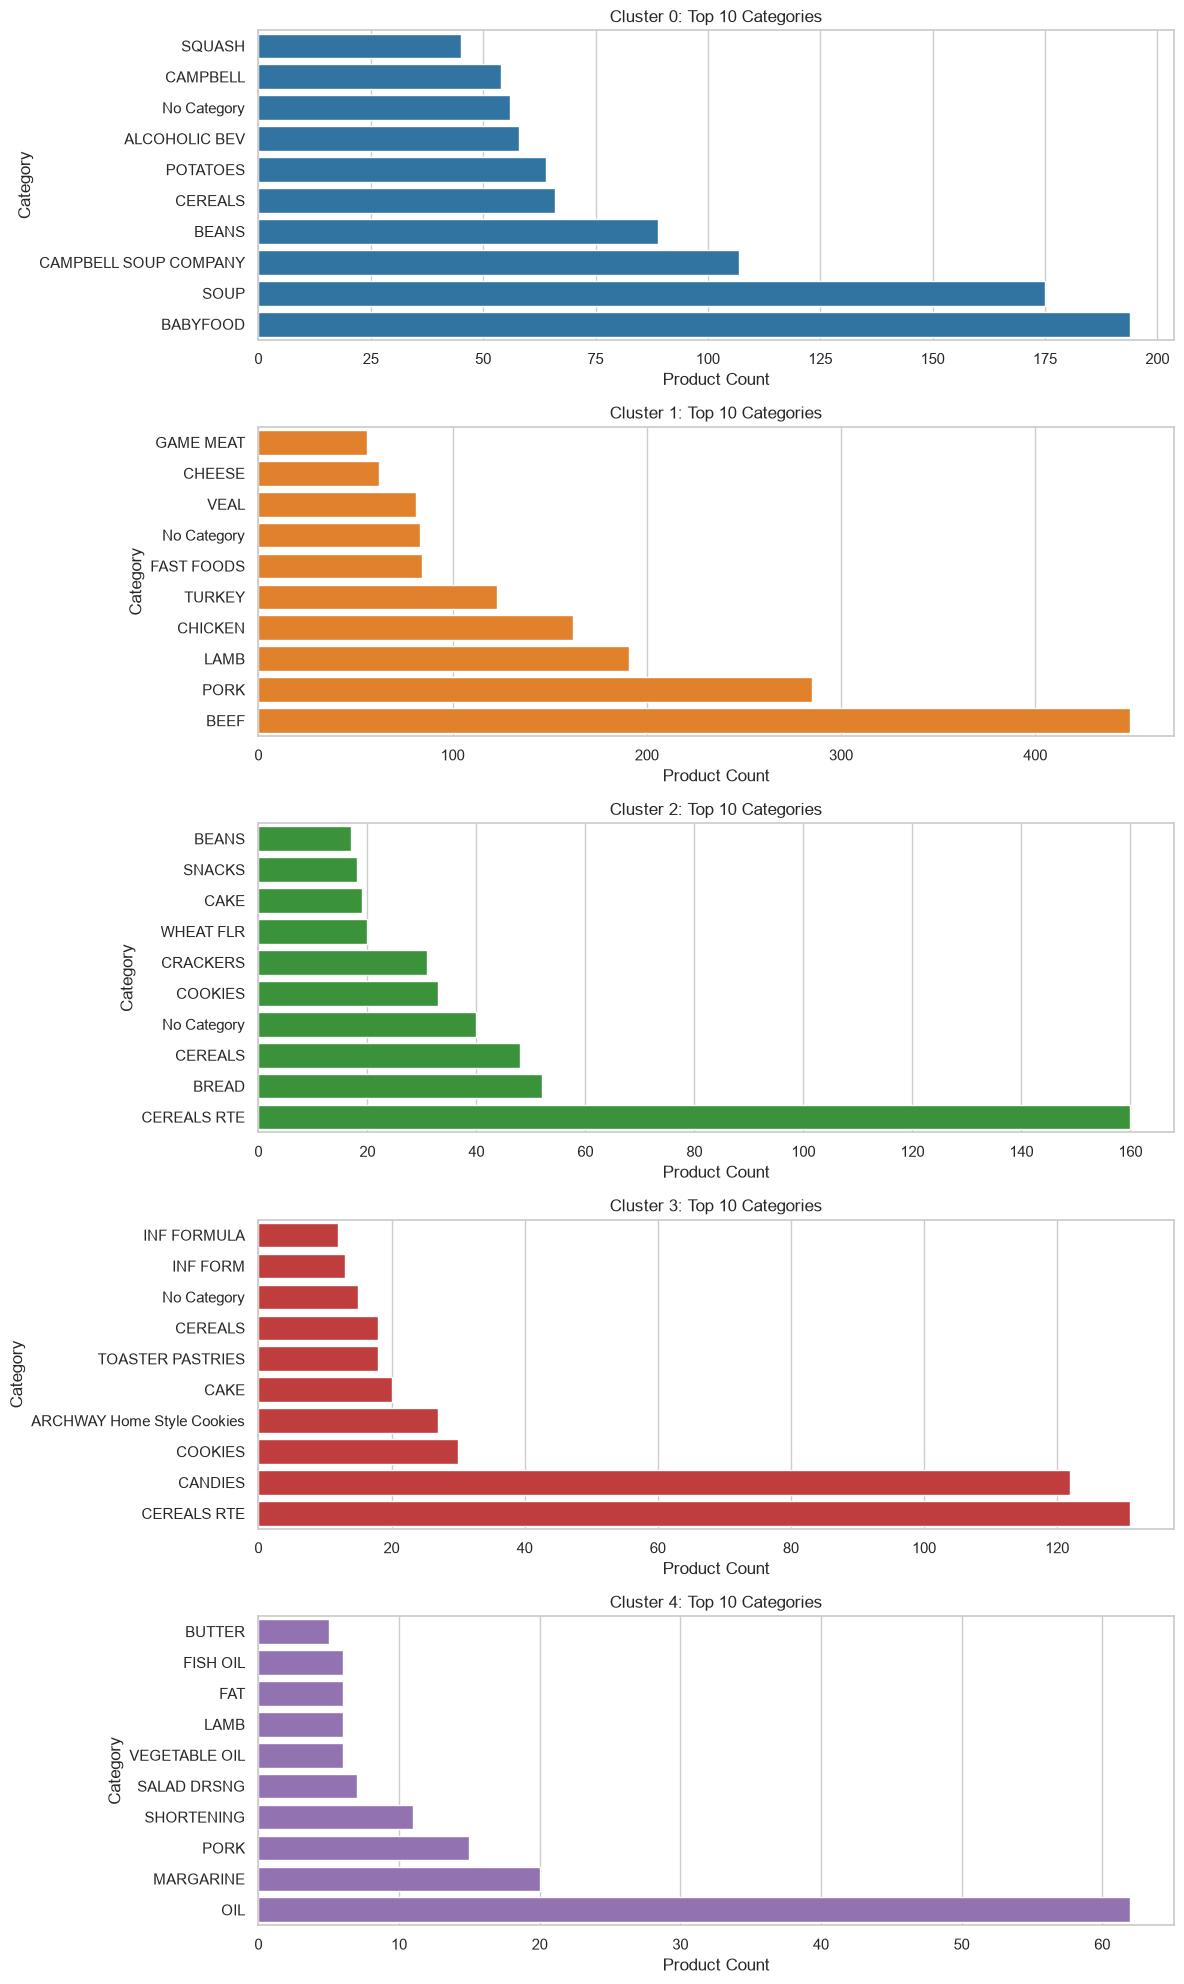

Dominant category by cluster: {0: 'BABYFOOD', 1: 'BEEF', 2: 'CEREALS RTE', 3: 'CEREALS RTE', 4: 'OIL'}
Overall cluster purity: 0.134


,Cluster,Category,Count,Share within Cluster
20,0,BABYFOOD,194,0.067385
662,1,BEEF,449,0.176078
1061,2,CEREALS RTE,160,0.139738
1308,3,CEREALS RTE,131,0.208599
1433,4,OIL,62,0.293839


In [16]:
composition = (
    results.groupby(["Cluster", "Category"])
    .size()
    .reset_index(name="Count")
)
composition["Cluster Total"] = composition.groupby("Cluster")["Count"].transform("sum")
composition["Share within Cluster"] = composition["Count"] / composition["Cluster Total"]
composition = composition.sort_values(["Cluster", "Count"], ascending=[True, False])
composition.to_csv(OUTPUT_DIR / "cluster_category_composition_full.csv", index=False)

top_composition = composition.groupby("Cluster", group_keys=False).head(TOP_CATEGORIES)
top_composition.to_csv(OUTPUT_DIR / "cluster_category_top10.csv", index=False)
display(top_composition)

fig, axes = plt.subplots(CHOSEN_K, 1, figsize=(12, 4 * CHOSEN_K))
for cluster_id, ax in zip(range(CHOSEN_K), np.atleast_1d(axes)):
    part = top_composition[top_composition["Cluster"] == cluster_id].sort_values("Count")
    sns.barplot(data=part, x="Count", y="Category", ax=ax, color=sns.color_palette("tab10")[cluster_id])
    ax.set_title(f"Cluster {cluster_id}: Top {TOP_CATEGORIES} Categories")
    ax.set_xlabel("Product Count")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "top_categories_by_cluster.png", dpi=200, bbox_inches="tight")
plt.show()

# Purity: sum of the dominant-label count in each cluster divided by total records.
dominant_rows = composition.loc[composition.groupby("Cluster")["Count"].idxmax()].copy()
dominant_map = dominant_rows.set_index("Cluster")["Category"].to_dict()
purity = dominant_rows["Count"].sum() / len(results)
print("Dominant category by cluster:", dominant_map)
print(f"Overall cluster purity: {purity:.3f}")
display(dominant_rows[["Cluster", "Category", "Count", "Share within Cluster"]])

## 5.2 Dominant-label mapping and readable confusion analysis

Each cluster is mapped to its most frequent category. A full confusion matrix would be extremely large because the dataset contains many labels, so this notebook:

- saves the full actual-versus-mapped table,
- prints the most frequent confusions,
- plots a readable matrix for the most common actual categories plus an `OTHER` bucket.

This preserves the requested method without pretending that a thousand-label chart is readable.

Most frequent off-diagonal confusions:


,Category,Mapped Label,Count,Correct Mapping
973,PORK,BEEF,285,False
624,LAMB,BEEF,191,False
1143,SOUP,BABYFOOD,175,False
236,CHICKEN,BEEF,162,False
172,CANDIES,CEREALS RTE,127,False
1279,TURKEY,BEEF,123,False
155,CAMPBELL SOUP COMPANY,BABYFOOD,107,False
65,BEANS,BABYFOOD,89,False
424,FAST FOODS,BEEF,84,False
831,No Category,BEEF,83,False


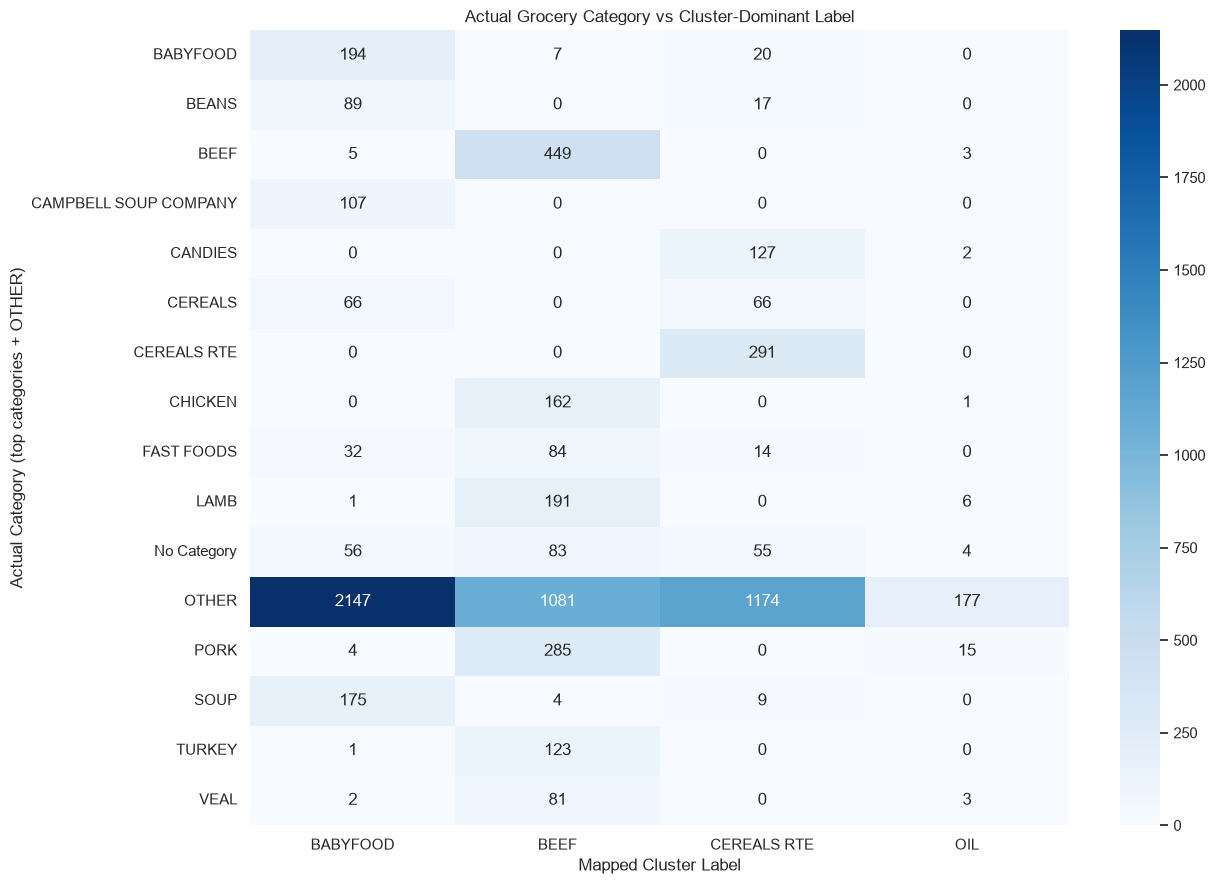

In [17]:
results["Mapped Label"] = results["Cluster"].map(dominant_map)
confusion_long = (
    results.groupby(["Category", "Mapped Label"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)
confusion_long["Correct Mapping"] = confusion_long["Category"] == confusion_long["Mapped Label"]
confusion_long.to_csv(OUTPUT_DIR / "confusion_actual_vs_mapped_full.csv", index=False)

print("Most frequent off-diagonal confusions:")
display(confusion_long[~confusion_long["Correct Mapping"]].head(25))

TOP_ACTUAL_N = 15
top_actual = results["Category"].value_counts().head(TOP_ACTUAL_N).index
conf_plot = results[["Category", "Mapped Label"]].copy()
conf_plot["Actual Display"] = np.where(conf_plot["Category"].isin(top_actual), conf_plot["Category"], "OTHER")
cm_table = pd.crosstab(conf_plot["Actual Display"], conf_plot["Mapped Label"])
cm_table.to_csv(OUTPUT_DIR / "confusion_matrix_readable.csv")

plt.figure(figsize=(13, 9))
sns.heatmap(cm_table, annot=True, fmt="g", cmap="Blues")
plt.title("Actual Grocery Category vs Cluster-Dominant Label")
plt.xlabel("Mapped Cluster Label")
plt.ylabel("Actual Category (top categories + OTHER)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix_readable.png", dpi=200, bbox_inches="tight")
plt.show()

## 5.3 Silhouette coefficients

Silhouette values range from -1 to 1:

- values closer to **1** indicate a cohesive point far from neighboring clusters,
- values near **0** indicate overlap near cluster boundaries,
- negative values suggest possible assignment to the wrong cluster.

Overall average silhouette: 0.429


,count,mean,median,min,max
Cluster,,,,,
0,2879,0.581,0.649,0.031,0.716
1,2550,0.372,0.401,-0.091,0.567
2,1145,0.198,0.224,-0.260,0.430
3,628,0.391,0.434,-0.109,0.559
4,211,0.393,0.451,-0.122,0.594


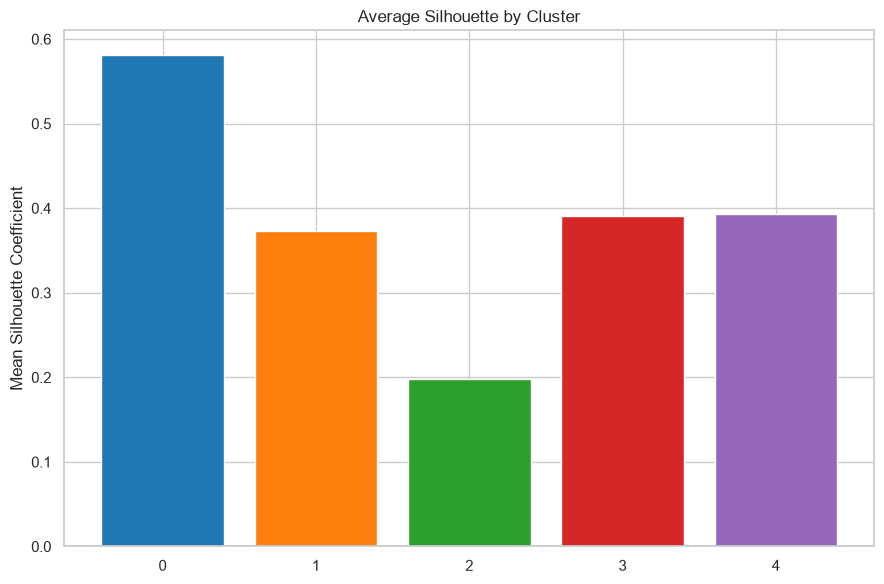

Items nearest to, or beyond, cluster boundaries:


,Category,Description,Cluster,Mapped Label,Silhouette
3677,BREADFRUIT SEEDS,"BREADFRUIT SEEDS,ROASTED",2,CEREALS RTE,-0.260182
5694,PANCAKES,"PANCAKES,PLN,FRZ,RTH,MICROWAVE(INC BUTTMLK)",2,CEREALS RTE,-0.227609
5674,PILLSBURY,"PILLSBURY,BTTRMLK BISCUITS,ART FLAVOR,REFR DOUGH",2,CEREALS RTE,-0.209995
6096,FROZEN NOVELTIES,"FROZEN NOVELTIES,KLONDIKE,SLIM-A-BEAR MINT SNDWCH",2,CEREALS RTE,-0.202853
6094,FROZEN NOVELTIES,"FROZEN NOVELTIES,KLONDIKE,SLIM-A-BEAR VANILLA ...",2,CEREALS RTE,-0.201401
6605,KENTUCKY FRIED CHICK,"KENTUCKY FRIED CHICK,POTATO WEDGES,ANALYZED PR...",2,CEREALS RTE,-0.199456
5507,ROLLS,"ROLLS,HAMBURGER OR HOTDOG,RED-CAL",2,CEREALS RTE,-0.198030
6092,FROZEN NOVELTIES,"FROZEN NOVELTIES,KLONDIKE,SLIM-A-BEAR VANILLA ...",2,CEREALS RTE,-0.194749
5427,ENGLISH MUFFIN,"ENGLISH MUFFIN, PLN,ENCHED.W/CA PROP (INCLD SO...",2,CEREALS RTE,-0.192390
5500,ROLLS,"ROLLS,DINNER,OAT BRAN",2,CEREALS RTE,-0.186761


In [18]:
results["Silhouette"] = silhouette_samples(X_scaled, cluster_labels)
average_silhouette = silhouette_score(X_scaled, cluster_labels)

silhouette_by_cluster = (
    results.groupby("Cluster")["Silhouette"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_index()
)
silhouette_by_cluster.to_csv(OUTPUT_DIR / "silhouette_by_cluster.csv")
print(f"Overall average silhouette: {average_silhouette:.3f}")
display(silhouette_by_cluster.round(3))

plt.figure(figsize=(9, 6))
plt.bar(silhouette_by_cluster.index.astype(str), silhouette_by_cluster["mean"], color=sns.color_palette("tab10", n_colors=len(silhouette_by_cluster)))
plt.axhline(0, color="black", linewidth=1)
plt.ylabel("Mean Silhouette Coefficient")
plt.title("Average Silhouette by Cluster")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "silhouette_by_cluster.png", dpi=200, bbox_inches="tight")
plt.show()

boundary_cases = results.nsmallest(30, "Silhouette")[["Category", "Description", "Cluster", "Mapped Label", "Silhouette"]]
boundary_cases.to_csv(OUTPUT_DIR / "lowest_silhouette_items.csv", index=False)
print("Items nearest to, or beyond, cluster boundaries:")
display(boundary_cases)

# Deliverable 6: Presentation Evidence

## 6.1 Name the product tribes

The following cell automatically summarizes each cluster using its most distinctive standardized centroid features and its leading categories. Use these facts to assign clear management-friendly names such as “high-water produce,” “fat-dense foods,” or “carbohydrate-heavy products.”

In [19]:
tribe_rows = []
for c in range(CHOSEN_K):
    zrow = centroids_z.loc[c]
    strongest_high = zrow.sort_values(ascending=False).head(3)
    strongest_low = zrow.sort_values().head(2)
    cats = top_composition[top_composition["Cluster"] == c].head(5)["Category"].tolist()
    tribe_rows.append({
        "Cluster": c,
        "Size": int((results["Cluster"] == c).sum()),
        "Highest relative nutrients": "; ".join(f"{k.replace('Data.', '')} ({v:+.2f} SD)" for k, v in strongest_high.items()),
        "Lowest relative nutrients": "; ".join(f"{k.replace('Data.', '')} ({v:+.2f} SD)" for k, v in strongest_low.items()),
        "Top categories": "; ".join(cats),
        "Mean silhouette": silhouette_by_cluster.loc[c, "mean"],
    })
tribes = pd.DataFrame(tribe_rows)
tribes.to_csv(OUTPUT_DIR / "management_cluster_tribes.csv", index=False)
display(tribes)

,Cluster,Size,Highest relative nutrients,Lowest relative nutrients,Top categories,Mean silhouette
0,0,2879,Water (+0.85 SD); Fiber (-0.12 SD); Sugar Tota...,Kilocalories (-0.84 SD); Protein (-0.76 SD),BABYFOOD; SOUP; CAMPBELL SOUP COMPANY; BEANS; ...,0.581114
1,1,2550,Protein (+1.05 SD); Fat.Saturated Fat (+0.17 S...,Carbohydrate (-0.66 SD); Sugar Total (-0.42 SD),BEEF; PORK; LAMB; CHICKEN; TURKEY,0.372487
2,2,1145,Carbohydrate (+1.48 SD); Fiber (+1.19 SD); Kil...,Water (-1.40 SD); Fat.Saturated Fat (-0.12 SD),CEREALS RTE; BREAD; CEREALS; No Category; COOKIES,0.198039
3,3,628,Sugar Total (+2.85 SD); Carbohydrate (+1.84 SD...,Water (-1.50 SD); Protein (-0.49 SD),CEREALS RTE; CANDIES; COOKIES; ARCHWAY Home St...,0.390893
4,4,211,Fat.Total Lipid (+4.52 SD); Fat.Saturated Fat ...,Water (-1.49 SD); Protein (-0.80 SD),OIL; MARGARINE; PORK; SHORTENING; SALAD DRSNG,0.393404


## 6.2 Wellness-gap scan

The dataset does not contain a verified health-claim field, so this is an exploratory text scan of product descriptions. It flags descriptions containing wellness-related terms and compares where they cluster. This must be described as a screening method, not proof that a product is healthy or unhealthy.

In [20]:
wellness_pattern = r"LOW[- ]?(?:FAT|SODIUM|CALORIE)|FAT[- ]?FREE|SUGAR[- ]?FREE|NO ADDED SUGAR|LIGHT|LITE|LEAN|WHOLE GRAIN|HIGH[- ]?FIBER|HEALTHY"
results["Wellness Wording"] = results["Description"].str.contains(wellness_pattern, case=False, regex=True, na=False)

wellness_by_cluster = pd.crosstab(results["Cluster"], results["Wellness Wording"])
wellness_by_cluster.to_csv(OUTPUT_DIR / "wellness_wording_by_cluster.csv")
display(wellness_by_cluster)

# Flag wellness-worded items in clusters whose centroid is above average in calories, sugar,
# total lipid, or saturated fat. This is a transparent project heuristic, not a medical judgment.
energy_dense_features = ["Data.Kilocalories", "Data.Sugar Total", "Data.Fat.Saturated Fat", "Data.Fat.Total Lipid"]
cluster_risk_index = centroids_z[energy_dense_features].mean(axis=1)
higher_density_clusters = cluster_risk_index[cluster_risk_index > 0].index.tolist()

wellness_gaps = results[
    results["Wellness Wording"] & results["Cluster"].isin(higher_density_clusters)
][["Category", "Description", "Cluster", "Silhouette"] + energy_dense_features].sort_values("Silhouette", ascending=False)
wellness_gaps.to_csv(OUTPUT_DIR / "wellness_gap_candidates.csv", index=False)
print(f"Exploratory wellness-gap candidates: {len(wellness_gaps):,}")
display(wellness_gaps.head(30))

Wellness Wording,False,True
Cluster,,
0,2776,103
1,2525,25
2,1122,23
3,619,9
4,211,0


Exploratory wellness-gap candidates: 32


,Category,Description,Cluster,Silhouette,Data.Kilocalories,Data.Sugar Total,Data.Fat.Saturated Fat,Data.Fat.Total Lipid
6030,POPCORN,"POPCORN,SUGAR SYRUP/CARAMEL,FAT-FREE",3,0.521778,381,64.680000,0.200,1.40
5648,ARCHWAY Home Style Cookies,"ARCHWAY Home Style Cookies, Fat Free Oatmeal R...",3,0.514412,348,47.070000,0.320,1.51
5686,NABISCO,"NABISCO,NABISCO SNACKWELL'S FAT FREE DEVIL'S F...",3,0.473007,305,43.380001,0.427,1.09
5647,ARCHWAY HOME STYLE COOKIES,"ARCHWAY HOME STYLE COOKIES,FAT FREE DEVIL'S FD...",3,0.463292,338,41.200001,0.320,0.90
5689,USDA CMDTY,"USDA CMDTY,BAKERY FLR MIX LOW-FAT",2,0.403988,361,0.000000,0.850,4.70
6024,POTATO CHIPS,"POTATO CHIPS,LIGHT",2,0.377157,471,0.220000,4.160,20.80
6031,POTATO CHIPS,"POTATO CHIPS,FAT FREE,SALTED",2,0.370366,379,3.690000,0.150,0.60
6025,SNACKS,"SNACKS,POTATO CHIPS,FAT-FREE,MADE W/OLESTRA",2,0.369186,274,0.000000,0.240,0.70
7350,CEREALS RTE,"CEREALS RTE,WHEAT,BRAN,SHREDDED,PLN,SALT&SUGAR...",2,0.368544,334,1.000000,0.200,1.40
5586,COOKIES,"COOKIES,OATMEAL,COMMLY PREP,FAT-FREE",3,0.368521,326,41.900002,0.314,1.50


## 6.3 Inventory recommendations evidence

Use cluster sizes, centroid profiles, category composition, silhouette strength, and the wellness scan to make recommendations. Good recommendations should be conditional on the store's stated ethos and should avoid treating clusters as medical diagnoses.

,Count,Share
Cluster,,
0,2879,38.8%
1,2550,34.4%
2,1145,15.4%
3,628,8.5%
4,211,2.8%


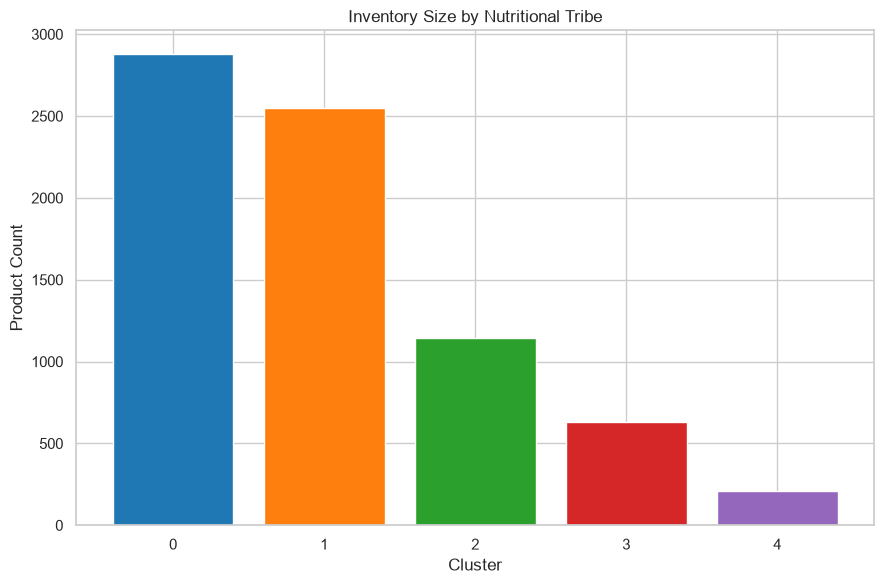

In [21]:
cluster_sizes = results["Cluster"].value_counts().sort_index().rename("Count").to_frame()
cluster_sizes["Share"] = cluster_sizes["Count"] / cluster_sizes["Count"].sum()
cluster_sizes.to_csv(OUTPUT_DIR / "cluster_sizes.csv")
display(cluster_sizes.style.format({"Share": "{:.1%}"}))

plt.figure(figsize=(9, 6))
plt.bar(cluster_sizes.index.astype(str), cluster_sizes["Count"], color=sns.color_palette("tab10", n_colors=len(cluster_sizes)))
plt.title("Inventory Size by Nutritional Tribe")
plt.xlabel("Cluster")
plt.ylabel("Product Count")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "cluster_sizes.png", dpi=200, bbox_inches="tight")
plt.show()

# Final automated export

The following cell saves the row-level clustered dataset and a concise text summary. At this point, the `outputs/` folder contains presentation-ready figures and analysis tables for all deliverables.

In [22]:
results.to_csv(OUTPUT_DIR / "food_with_clusters_and_silhouettes.csv", index=False)

summary_lines = [
    f"Rows analyzed: {len(results):,}",
    f"Numeric features: {len(EXPECTED_NUMERIC)}",
    f"Chosen k: {CHOSEN_K}",
    f"PC1 + PC2 variance captured: {pca_2.explained_variance_ratio_.sum():.2%}",
    f"Overall silhouette: {average_silhouette:.3f}",
    f"Cluster purity against source categories: {purity:.3f}",
    "Dominant category by cluster: " + str(dominant_map),
]
summary_text = "\n".join(summary_lines)
(OUTPUT_DIR / "analysis_summary.txt").write_text(summary_text, encoding="utf-8")

print(summary_text)
print(f"\nCompleted. Review files in: {OUTPUT_DIR.resolve()}")


Rows analyzed: 7,413
Numeric features: 8
Chosen k: 5
PC1 + PC2 variance captured: 67.38%
Overall silhouette: 0.429
Cluster purity against source categories: 0.134
Dominant category by cluster: {0: 'BABYFOOD', 1: 'BEEF', 2: 'CEREALS RTE', 3: 'CEREALS RTE', 4: 'OIL'}

Completed. Review files in: C:\Users\danie\AppData\Local\GitHub-Projects\transfer\Data-Design-Project\notebooks\outputs


# Suggested presentation structure

1. **Business question and dataset**: inventory scope and eight nutritional measurements.
2. **Data quality and distributions**: skewness, outliers, and the bimodal water pattern.
3. **Nutrient relationships**: correlation heatmap and strongest feature groups.
4. **Feature influence**: PCA variance and loadings.
5. **Choosing the number of tribes**: elbow curve and `k=5` justification.
6. **Inventory tribes**: centroid heatmap, top categories, and cluster sizes.
7. **Cluster confidence**: silhouette results and boundary cases.
8. **Wellness gaps**: clearly labeled exploratory examples from wellness wording.
9. **Recommendations**: changes linked directly to cluster size, centroid profile, and store ethos.
10. **Limitations**: source categories are numerous and inconsistent; clustering uses nutritional values rather than sales, price, demand, or verified health claims.